[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/06_hito5_lsst.ipynb)

# 06 · Hito 5: predicciones para LSST

**Qué pide el enunciado.** "Observar" las corrientes simuladas como lo haría LSST (footprint, profundidad,
errores de movimiento propio, distancias fotométricas, sin velocidades radiales), recalcular las métricas solo con
las estrellas observadas y responder: qué corrientes (y qué partes) podría detectar LSST y a qué distancias; para
cuáles la señal del reflejo supera los errores, y en qué métrica; cuántas corrientes harían falta para distinguir
el reflejo del tirón directo.

**Supuestos** (todos en `p3streams/config.py` y `p3streams/observar.py`):
- Población: isócrona PARSEC 12 Gyr, Z = 0.0002, bandas LSST, IMF de Chabrier. Masa estelar formada
  $M_* = 10^{-2}\,M_{\rm prog}$ (supuesto: los progenitores son enanas dominadas por materia oscura; se varía abajo).
- Cada partícula representa $M_*/N$; el número de estrellas sobre el límite se sortea con Poisson.
- Footprint Dec < +5°; profundidad r < 27 (10 años); movimientos propios para 16 < r < 24.5 con
  $\sigma_\mu$ = 0.2 mas/yr (r = 21) a 1.0 mas/yr (r = 24), interpolado en log (Ivezić et al. 2019);
  distancias fotométricas con 7 % de error; sin velocidades radiales.
- Seguimiento espectroscópico opcional (4MOST, DESI, PFS): r < 21, $\sigma_v$ = 2 km/s. Solo con él se calculan
  los polos orbitales (necesitan la velocidad completa).
- Gaia DR3 para comparar: G < 21 con G ≈ r y sus errores de movimiento propio (Lindegren et al. 2021, aproximados).
- Errores de las métricas: bootstrap (remuestreo de estrellas + nuevas realizaciones de los errores).
  Con más de 20 000 estrellas se usa un subconjunto al azar, así que esos errores son una **cota superior** y la
  señal/ruido `snr` es **conservadora**. La columna `snrx` reescala los errores por $\sqrt{N_{\rm usadas}/N_{\rm obs}}$
  [deducido: supone errores puramente estadísticos]; la verdad está entre las dos.

**Qué es observable de verdad.** El desalineamiento y la dispersión de los polos son *intrínsecos*: se miden en la
corriente sin saber cuál era su órbita inicial. Las inclinaciones (del polo y del plano) se miden **respecto del
polo inicial**, que no se observa: solo sirven comparando con modelos ajustados. Por eso el criterio de detección
compara modelos con las mismas condiciones iniciales ($|M_D - M_C|$ para el reflejo y $|M_D - M_B|$ para el tirón
directo, en unidades de su error, > 3σ), y el número de corrientes necesario es una **cota optimista**: supone
conocidos la MW, la LMC y los progenitores.

In [19]:
# Celda 1: entorno. En Colab clona el repositorio, instala versiones fijas y monta Google Drive (las salidas
# quedan en MyDrive/lapis26_p3/salidas). Si numpy cambia de version, la sesion se reinicia UNA vez:
# vuelve a ejecutar esta celda. En una maquina propia solo comprueba versiones.
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.18
  numpy       2.2.6
  scipy       1.16.3
  astropy     7.2.3
  gala        1.12.0
  matplotlib  3.10.0
  pandas      2.2.3
  healpy      1.20.1
  galstreams  1.2.1
Salidas en: /content/drive/MyDrive/lapis26_p3/salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [22]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("06_hito5_lsst")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/06_hito5_lsst.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: /content/drive/MyDrive/lapis26_p3/salidas/06_hito5_lsst_20261030_021244


In [23]:
from p3streams import resultados as R, analisis as An, metricas as Me, figuras as F, potenciales as P
PROPIOS = True
DF, ORIGEN = R.cargar("catalogo_principal", propios=PROPIOS)
print("Catalogo: %d corrientes, leido de %s" % (len(DF), ORIGEN))
sis = P.integrar_sistema()          # el mismo sistema MW + LMC (1.8e11 Msun) del catalogo
DF = An.agregar_geometria(DF, sis)
from p3streams import lsst as L, observar as O, corrientes as Co, catalogo as Ca
LS, ORIGEN_L = R.cargar("lsst_principal", propios=PROPIOS)
print("Pasada LSST: %d corrientes, leida de %s" % (len(LS), ORIGEN_L))
M = L.agregar_snr_escalada(DF.merge(LS, on="id", how="inner"))

Catalogo: 288 corrientes, leido de /content/drive/MyDrive/lapis26_p3/salidas/principal_20261029_140326
No hay corrida propia de lsst_principal en /content/drive/MyDrive/lapis26_p3/salidas: uso la incluida en el repositorio.
Pasada LSST: 288 corrientes, leida de /content/lapis26-p3-corrientes/resultados/lsst_principal.csv


### Una corriente vista por LSST

Se rehace una corriente larga del catálogo (las corrientes no vienen en el repositorio, solo su tabla) y se
observa en los modelos C y D.

In [24]:
FILA = DF[(DF["familia"] == "larga") & (DF["psi_deg"] == 0)].sort_values("dpolo_B_todo").iloc[-1].to_dict()
print("Corriente:", FILA["id"], "polo", np.round(FILA["polo"], 2))
CAT = os.path.join(SAL, "catalogo_local")
os.makedirs(os.path.join(CAT, "filas")); os.makedirs(os.path.join(CAT, "corrientes"))
base = {k: FILA[k] for k in ("id", "polo", "polo_idx", "sentido", "familia", "psi_deg", "f", "t_start", "r_apo", "m_prog")}
fila_local = Ca.correr_corriente(base, sis, CAT)
import json
with open(os.path.join(CAT, "filas", FILA["id"] + ".json"), "x") as f:
    json.dump(fila_local, f, default=float)
FL = O.FuncionLuminosidad()
CORR = {m: Co.cargar(os.path.join(CAT, "corrientes", "%s_%s.npz" % (FILA["id"], m))) for m in "CD"}
OBS = {m: O.observar(CORR[m], 1e-2 * FILA["m_prog"], np.random.default_rng(1), espectro=True, fl=FL) for m in "CD"}
lmc = Me.a_icrs(sis.x_lmc_rel(0.0)[None, :], ((sis._x_lmc(0.0, 1) - sis._x_mw(0.0, 1)) / P.KMS())[None, :], corregir=False)
LMC_RADEC = (lmc.ra.deg[0], lmc.dec.deg[0])
print("LMC hoy (modelo): RA %.1f, Dec %.1f deg" % LMC_RADEC)

Corriente: p03+_larga_f000 polo [ 0.28 -0.28  0.92]
LMC hoy (modelo): RA 78.7, Dec -69.0 deg


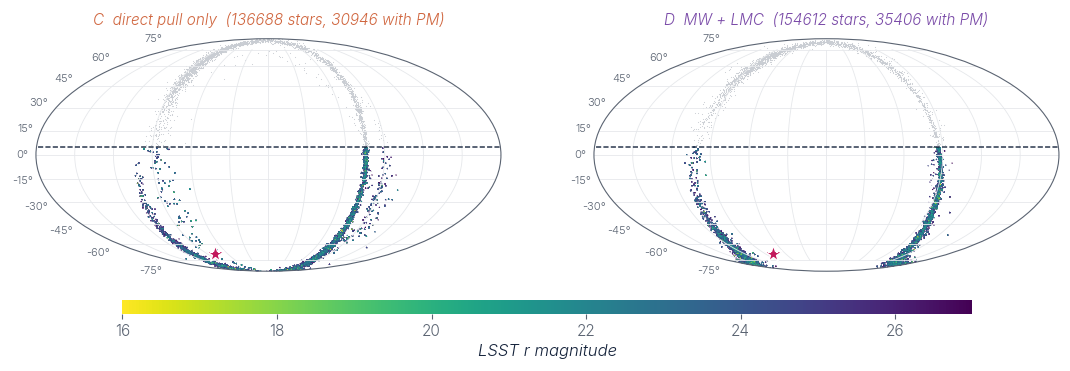

Figura: hito5_lsst_cielo.png 
Milestone 5, LSST view of one long stream of the catalogue (models C and D). Grey: all stream particles; coloured: stars LSST would detect after 10 years (r < 27, Dec < +5 deg, dashed line), drawn from a 12 Gyr, Z = 0.0002 PARSEC isochrone with M_* = 0.01 M_prog. Star: the LMC today in the model. Equatorial coordinates, Mollweide, RA increasing to the left.


In [25]:
fig = F.lsst_cielo(CORR, OBS, LMC_RADEC)
PIE = 'Milestone 5, LSST view of one long stream of the catalogue (models C and D). Grey: all stream particles; coloured: stars LSST would detect after 10 years (r < 27, Dec < +5 deg, dashed line), drawn from a 12 Gyr, Z = 0.0002 PARSEC isochrone with M_* = 0.01 M_prog. Star: the LMC today in the model. Equatorial coordinates, Mollweide, RA increasing to the left.'
E.guardar(fig, os.path.join(SAL, 'hito5_lsst_cielo.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito5_lsst_cielo.png', "\n" + PIE)

### ¿Qué se ve y a qué distancias?

In [26]:
T = M.groupby("familia").agg(frac_en_footprint=("frac_footprint_D", "median"), parte_del_largo=("psi_footprint_D", "median"),
                               estrellas_LSST=("n_obs_D", "median"), con_PM=("n_pm_D", "median"), Gaia_G21=("n_gaia_D", "median"),
                               d_mediana_kpc=("d_med_obs_D", "median"), d_max_kpc=("d_max_obs_D", "median"),
                               n_corrientes=("id", "size")).round(2)
T.to_csv(os.path.join(SAL, "hito5_lsst_visibilidad.csv"))
print("Corrientes sin ninguna estrella observada (modelo D):", int((M["n_obs_D"] == 0).sum()))
T

Corrientes sin ninguna estrella observada (modelo D): 0


,frac_en_footprint,parte_del_largo,estrellas_LSST,con_PM,Gaia_G21,d_mediana_kpc,d_max_kpc,n_corrientes
familia,,,,,,,,
corta,0.10,0.77,2837.0,563.5,28.5,65.82,140.23,96
doble,0.63,1.00,508218.0,5252.0,11190.0,26.94,82.87,96
larga,0.57,1.00,167119.0,4571.0,2229.5,36.82,117.60,96


### ¿Supera la señal a los errores?

Fracción de corrientes con señal > 3σ, por métrica y por variante: toda la corriente con LSST, cada brazo con
LSST, y toda la corriente con Gaia (G < 21, sin espectroscopía).

In [27]:
MET = {"desalineamiento_deg": "PM misalignment", "dispersion_polos_deg": "pole spread (needs RVs)",
       "tilt_polo_deg": "pole tilt (needs RVs; model comparison)", "tilt_plano_deg": "plane tilt (model comparison)"}
filas = []
for var in ("", "lider", "cola", "gaia"):
    pre = var + "_" if var else ""
    for met, nom in MET.items():
        r = M["snr_%sreflejo_%s" % (pre, met)].to_numpy(float)
        d = M["snr_%sdirecto_%s" % (pre, met)].to_numpy(float)
        rx = M["snrx_%sreflejo_%s" % (pre, met)].to_numpy(float)
        dx = M["snrx_%sdirecto_%s" % (pre, met)].to_numpy(float)
        filas.append(dict(variant={"": "LSST, whole stream", "lider": "LSST, leading arm", "cola": "LSST, trailing arm",
                                   "gaia": "Gaia (G < 21)"}[var], metric=nom,
                          measurable=np.mean(np.isfinite(r)), reflex_gt_3sigma=np.nanmean(r > 3) if np.isfinite(r).any() else np.nan,
                          direct_gt_3sigma=np.nanmean(d > 3) if np.isfinite(d).any() else np.nan,
                          reflex_gt_3sigma_scaled=np.nanmean(rx > 3) if np.isfinite(rx).any() else np.nan,
                          direct_gt_3sigma_scaled=np.nanmean(dx > 3) if np.isfinite(dx).any() else np.nan,
                          median_snr_reflex=np.nanmedian(r) if np.isfinite(r).any() else np.nan))
DET = pd.DataFrame(filas).round(2)
DET.to_csv(os.path.join(SAL, "hito5_lsst_deteccion.csv"), index=False)
DET

,variant,metric,measurable,reflex_gt_3sigma,direct_gt_3sigma,reflex_gt_3sigma_scaled,direct_gt_3sigma_scaled,median_snr_reflex
0,"LSST, whole stream",PM misalignment,0.95,0.08,0.04,0.46,0.41,1.15
1,"LSST, whole stream",pole spread (needs RVs),0.83,0.44,0.45,0.67,0.62,3.52
2,"LSST, whole stream",pole tilt (needs RVs; model comparison),0.83,0.34,0.46,0.59,0.61,2.27
3,"LSST, whole stream",plane tilt (model comparison),1.00,0.94,0.94,0.97,0.96,24.14
4,"LSST, leading arm",PM misalignment,0.92,0.11,0.07,0.49,0.45,1.19
5,"LSST, leading arm",pole spread (needs RVs),0.81,0.44,0.32,0.65,0.57,3.16
6,"LSST, leading arm",pole tilt (needs RVs; model comparison),0.81,0.34,0.40,0.59,0.58,2.43
7,"LSST, leading arm",plane tilt (model comparison),1.00,0.93,0.92,0.97,0.97,22.61
8,"LSST, trailing arm",PM misalignment,0.83,0.08,0.08,0.48,0.43,1.20
9,"LSST, trailing arm",pole spread (needs RVs),0.76,0.26,0.30,0.54,0.52,2.15


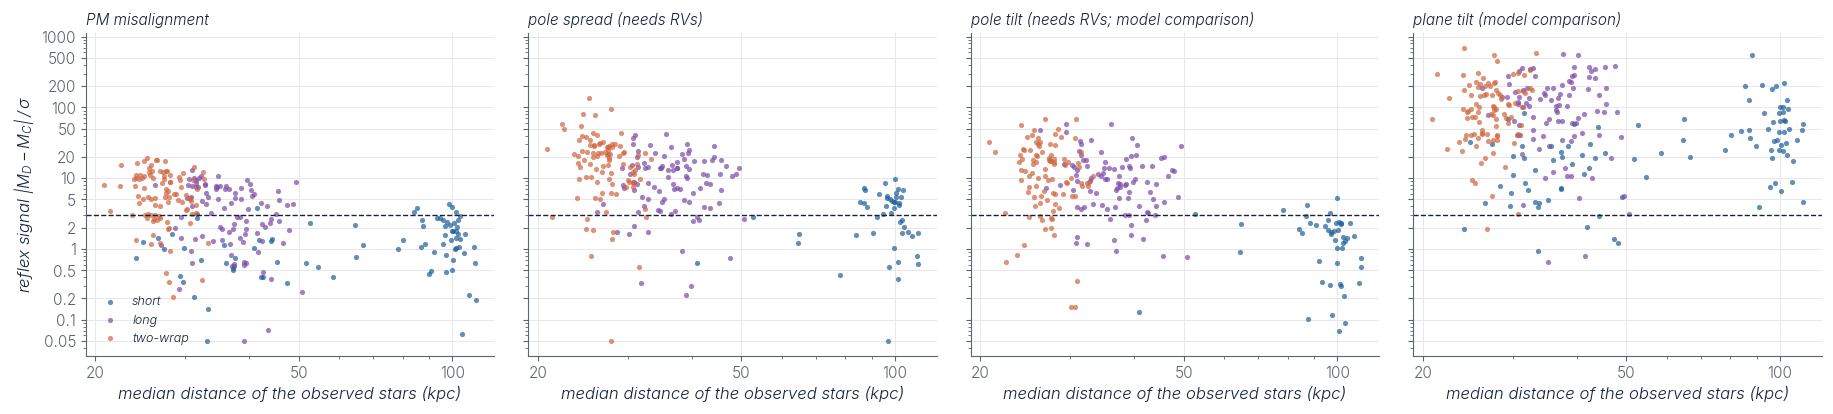

Figura: hito5_lsst_snr.png 
Milestone 5. Reflex signal in the metrics recomputed from the stars LSST would observe: |M_D - M_C| (with and without the reflex motion, same initial conditions) divided by its bootstrap uncertainty (bootstrap on at most 20 000 stars, rescaled by sqrt(N_used/N_observed) to all observed stars, assuming purely statistical errors), against the median distance of the observed stars. Dashed: 3 sigma. Metrics marked 'needs RVs' use spectroscopic follow-up for r < 21; 'model comparison' metrics are measured relative to the unobservable initial pole.


In [28]:
fig = F.lsst_snr(M, list(MET), [MET[k] for k in MET], col="snrx")
PIE = "Milestone 5. Reflex signal in the metrics recomputed from the stars LSST would observe: |M_D - M_C| (with and without the reflex motion, same initial conditions) divided by its bootstrap uncertainty (bootstrap on at most 20 000 stars, rescaled by sqrt(N_used/N_observed) to all observed stars, assuming purely statistical errors), against the median distance of the observed stars. Dashed: 3 sigma. Metrics marked 'needs RVs' use spectroscopic follow-up for r < 21; 'model comparison' metrics are measured relative to the unobservable initial pole."
E.guardar(fig, os.path.join(SAL, 'hito5_lsst_snr.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito5_lsst_snr.png', "\n" + PIE)

### Lista de corrientes y regiones con reflejo detectable en una métrica intrínseca

In [29]:
filas = []
for _, f in M.iterrows():
    for var, reg in (("", "whole"), ("lider", "leading arm"), ("cola", "trailing arm")):
        pre = var + "_" if var else ""
        for met in ("desalineamiento_deg", "dispersion_polos_deg"):
            v = f.get("snr_%sreflejo_%s" % (pre, met), np.nan)
            vx = f.get("snrx_%sreflejo_%s" % (pre, met), np.nan)
            if np.isfinite(vx) and vx > 3:
                filas.append(dict(id=f["id"], family=f["familia"], region=reg, metric=MET[met], snr_reflex=round(v, 1),
                                  snr_reflex_scaled=round(vx, 1),
                                  d_med_kpc=round(f["d_med_obs_D"], 1), peri_kpc=round(f["peri_kpc"], 1)))
LISTA = pd.DataFrame(filas)
LISTA.to_csv(os.path.join(SAL, "hito5_lsst_lista_reflejo_detectable.csv"), index=False)
print("Corrientes con al menos una region/metrica intrinseca > 3 sigma (snr reescalada): %d de %d"
      % (LISTA["id"].nunique() if len(LISTA) else 0, len(M)))
if len(LISTA):
    print("  solo con el desalineamiento (sin velocidades radiales): %d"
          % LISTA.loc[LISTA["metric"] == MET["desalineamiento_deg"], "id"].nunique())
    print("  con la version conservadora: %d" % LISTA.loc[LISTA["snr_reflex"] > 3, "id"].nunique())
LISTA.sort_values("snr_reflex_scaled", ascending=False).head(25) if len(LISTA) else LISTA

Corrientes con al menos una region/metrica intrinseca > 3 sigma (snr reescalada): 231 de 288
  solo con el desalineamiento (sin velocidades radiales): 199
  con la version conservadora: 194


,id,family,region,metric,snr_reflex,snr_reflex_scaled,d_med_kpc,peri_kpc
134,p07+_doble_f000,doble,whole,pole spread (needs RVs),23.1,134.3,25.2,11.5
759,p39+_doble_f000,doble,leading arm,pole spread (needs RVs),25.4,121.7,28.8,11.5
714,p37+_doble_f000,doble,whole,pole spread (needs RVs),18.2,94.2,27.8,11.5
548,p28+_doble_f090,doble,whole,pole spread (needs RVs),15.9,79.7,24.5,11.7
880,p44+_doble_f090,doble,trailing arm,pole spread (needs RVs),15.4,78.5,26.0,11.5
139,p07+_doble_f090,doble,whole,pole spread (needs RVs),12.2,77.1,25.9,11.6
832,p42+_doble_f090,doble,leading arm,pole spread (needs RVs),12.6,74.8,22.5,11.6
860,p43+_doble_f090,doble,trailing arm,pole spread (needs RVs),12.1,63.4,23.6,11.6
834,p42+_doble_f090,doble,trailing arm,pole spread (needs RVs),10.0,59.8,22.5,11.6
602,p31+_doble_f000,doble,leading arm,pole spread (needs RVs),11.7,58.3,27.9,11.5


### ¿Cuántas corrientes harían falta?

Corrientes tomadas al azar del catálogo (en el footprint) hasta que su señal combinada en cuadratura supera
3σ; mediana y rango 16-84 % de 4000 sorteos. Cota optimista (ver arriba).

In [30]:
filas = []
for var in ("", "gaia"):
    pre = var + "_" if var else ""
    for met, nom in MET.items():
        for efecto in ("reflejo", "directo"):
            n50, n16, n84 = L.n_necesarias(M["snr_%s%s_%s" % (pre, efecto, met)])
            x50, _, _ = L.n_necesarias(M["snrx_%s%s_%s" % (pre, efecto, met)])
            filas.append(dict(survey="Gaia" if var else "LSST", metric=nom, effect={"reflejo": "reflex", "directo": "direct pull"}[efecto],
                              n_streams_median=n50, n16=n16, n84=n84, n_streams_scaled=x50))
NN = pd.DataFrame(filas)
NN.to_csv(os.path.join(SAL, "hito5_lsst_n_necesarias.csv"), index=False)
NN

,survey,metric,effect,n_streams_median,n16,n84,n_streams_scaled
0,LSST,PM misalignment,reflex,4.0,2.00,7.00,2.0
1,LSST,PM misalignment,direct pull,5.0,2.00,7.00,2.0
2,LSST,pole spread (needs RVs),reflex,1.0,1.00,3.00,1.0
3,LSST,pole spread (needs RVs),direct pull,1.0,1.00,2.00,1.0
4,LSST,pole tilt (needs RVs; model comparison),reflex,2.0,1.00,3.00,1.0
5,LSST,pole tilt (needs RVs; model comparison),direct pull,1.0,1.00,2.16,1.0
6,LSST,plane tilt (model comparison),reflex,1.0,1.00,1.00,1.0
7,LSST,plane tilt (model comparison),direct pull,1.0,1.00,1.00,1.0
8,Gaia,PM misalignment,reflex,8.0,4.00,12.00,8.0
9,Gaia,PM misalignment,direct pull,9.0,4.84,14.00,9.0


### Sensibilidad a la masa estelar supuesta

Con $M_*/M_{\rm prog}$ diez veces menor hay diez veces menos estrellas. Se observa de nuevo la corriente de arriba,
esta vez **con todas las estrellas** (sin el tope de 20 000), para que la comparación sea justa.

In [31]:
filas = []
for frac in (1e-2, 1e-3):
    r = L.observar_corriente(FILA["id"], CAT, fl=FL, frac=frac, n_boot=10, variantes=("lsst",), n_max=10**7)   # sin tope
    filas.append(dict(M_star_over_M_prog=frac, n_obs_D=r["n_obs_D"], n_pm_D=r.get("n_pm_D"),
                      **{"snr_reflex_" + k: r.get("snr_reflejo_" + k) for k in MET}))
pd.DataFrame(filas).round(2)

,M_star_over_M_prog,n_obs_D,n_pm_D,snr_reflex_desalineamiento_deg,snr_reflex_dispersion_polos_deg,snr_reflex_tilt_polo_deg,snr_reflex_tilt_plano_deg
0,0.01,155397,35627,2.32,35.57,23.06,225.90
1,0.00,15560,3534,3.90,10.46,5.24,69.47


## Discusión: predicciones para LSST

Números de la corrida incluida (288 corrientes, $M_* = 10^{-2}\,M_{\rm prog}$, 10 años). `snr`: conservadora
(como mucho 20 000 estrellas); `snrx`: errores reescalados a todas las estrellas observadas [deducido].

**¿Qué ve LSST y a qué distancia?** [comprobado] Todas las corrientes tienen estrellas sobre el límite. Las de
dos vueltas (40 kpc) y las largas (60 kpc) caen en ~60 % dentro del footprint y LSST cubre toda su extensión en
ángulo, con mediana de ~27 y ~37 kpc y estrellas hasta ~80–120 kpc. Las cortas (100 kpc) son el caso difícil:
solo ~10 % de sus estrellas cae en el footprint, con ~2800 estrellas observadas y ~560 con movimiento propio
(mediana a ~66 kpc, hasta ~140 kpc).

**¿Supera la señal del reflejo a los errores?** [comprobado, salvo donde se indica]
- *Desalineamiento* (solo posiciones, distancias y movimientos propios): >3σ en ~8 % de las corrientes con la
  versión conservadora y en ~46 % con la reescalada [deducido]. Por familia, con la reescalada: ~78 % de las de
  dos vueltas, ~53 % de las largas y solo ~7 % de las cortas.
- *Dispersión de los polos* (necesita velocidades radiales, r < 21): >3σ en ~44–67 %.
- *Inclinaciones* (comparan con el polo inicial, que no se observa): 34–97 %. Sirven solo dentro de un ajuste de
  modelos.
- *Gaia* (G < 21): el desalineamiento se mide en ~la mitad de las corrientes y casi nunca supera 3σ (~1 %).
  **LSST es lo que hace observable esta señal** a estas distancias.

**La tensión principal** [deducido de lo anterior y del notebook 05]: las corrientes **dominadas por el reflejo**
son las lejanas, y son justo las que LSST ve peor (pocas estrellas, casi todas fuera del footprint del sur). Donde
LSST mide bien (corrientes internas, largas) la señal del reflejo existe (D ≠ C), pero ahí domina el tirón
directo. Separar los dos efectos va a depender de pocas corrientes externas bien medidas, o de seguimiento
espectroscópico.

**¿Cuántas corrientes?** Combinando corrientes al azar, el desalineamiento llega a 3σ con ~2–4 corrientes y la
dispersión de los polos con 1–2 [comprobado]. Son cotas **optimistas**: suponen conocidos la MW, la LMC y los
progenitores. En un análisis real hay que marginalizar sobre ellos, y el número crece [deducido, sin cuantificar].

**Cuidado con el desalineamiento observado** [comprobado en la última tabla]: con diez veces menos estrellas, la
dispersión de los polos y las inclinaciones pierden señal/ruido como se espera (~×3), pero la del desalineamiento
*sube* (2.3 → 3.9). Eso indica que la medición fluctúa entre realizaciones del muestreo más de lo que dice su error
de bootstrap: además, la mediana de $|\Delta\theta|$ está sesgada hacia arriba por el ruido. Hay que leer la
señal/ruido del desalineamiento como incierta en un factor ~2 [deducido]. Para un análisis real convendría repetir
la observación con varias semillas.

**Límites del modelo de observación.** Un solo valor de $M_*/M_{\rm prog}$ (se prueba ×0.1 en una corriente); sin
polvo ni contaminación de campo; errores de LSST interpolados entre dos puntos de Ivezić et al. (2019); el ángulo
a lo largo de la corriente viene de la simulación (en datos reales hay que ajustar la traza); Gaia aproximada con
G ≈ r.

In [32]:
U.escribir_texto("Hito 5 LSST (%s): %d corrientes; deteccion por metrica en hito5_lsst_deteccion.csv."
                 % (U.ahora(), len(M)), os.path.join(SAL, "registro.txt"))